# LUMYVUE V6 — Run 02 evidence notebook (read-only)

**What this is.** A read-only record of what the `open_run02` run produced: training curves, selection results, evaluation tables, the V5 vs V6 comparison, the export checks and the gate board. Every number below is read from files the run saved (`astra_runs/open_run02/`). Nothing is trained, recomputed from images, or written back to the run folder, and the locked test split is never touched.

**Honest reading rules (carry these into the thesis).**
- The run is **development-stage**. The locked test split was **not evaluated** (it has no expert labels and about 85 % of it was in V5's training data).
- Labels are **researcher-reviewed**, partly AI-assisted (recorded as such). They are not dermatologist-verified.
- Fusion-split metrics are out-of-fold but mostly on images V5 also trained on, so they are **not** a V5 comparison. The V5 comparison uses validation images V5 never trained on (section 8).
- Results are a single seed (42). Intervals are wide because the fair set has 132 images (47 hyperpigmentation positives, 26 all-negative, 18 eczema positives).

In [1]:
import json, os, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

CANDIDATES = [os.environ.get("LUMYVUE_RUN_DIR", ""),
              "/mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02",
              r"C:\Users\Bautista\source\repos\SkinDevApp\v6\astra_runs\open_run02",
              "/mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/backups/open_run02_complete_20261102_1715",
              r"C:\Users\Bautista\source\repos\SkinDevApp\v6\backups\open_run02_complete_20261102_1715"]
RUN = next((Path(c) for c in CANDIDATES if c and (Path(c) / "metrics").is_dir()), None)
assert RUN is not None, "run folder not found: set LUMYVUE_RUN_DIR"
M = RUN / "metrics"
print("reading from:", RUN)

reading from: /mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02


## 1. Run identity and integrity

In [2]:
fs = json.load(open(RUN / "report" / "final_summary.json"))
show = {k: v for k, v in fs.items() if k != "unit_tests"}
print(json.dumps(show, indent=1))
ut = fs["unit_tests"]; print(f"\nunit tests: ran {ut['ran']}, passed {ut['passed']}, failures {len(ut['failures'])}, errors {len(ut['errors'])}, skipped {len(ut['skipped'])}")
for s in ut["skipped"]: print("  skipped:", s[0].split(" ")[0], "-", s[1])
print("\ngate board:"); display(pd.read_csv(RUN / "report" / "stage_gate_board.csv"))

{
 "run_id": "open_run02",
 "finished": "2026-11-02T16:54:05",
 "originals_unchanged": true,
 "changed_originals": [],
 "audit_chain_intact": true,
 "gates_open": 9,
 "gates_blocked": 3,
 "artifacts": 6139,
 "test_split_evaluated": false,
 "trained": {
  "global_selected": [
   "E_v5_backbone_multilabel3",
   42
  ],
  "roi_seed": 42,
  "fusion_variants": [
   "full",
   "global_yolo",
   "global_only",
   "roi_only",
   "no_acne_evidence",
   "no_eczema_evidence",
   "no_hyper_evidence"
  ]
 },
 "dermatologist_review_required_for_every_assessment": true,
 "review_status_at_issue": "PENDING_DERMATOLOGIST_REVIEW",
 "honesty": "Values appear only in files produced by this run. Where a stage was blocked, its outputs do not exist and no placeholder was created."
}

unit tests: ran 37, passed 35, failures 0, errors 0, skipped 2
  skipped: test_end_to_end_reference_parity_with_batch_logic - needs all trained components and the evaluated test split
  skipped: test_unknown_is_not_negative - we

,gate,open,reason
0,provenance_defined,True,NaN
1,annotations_train,True,NaN
2,annotations_validation,True,NaN
3,annotations_fusion,True,NaN
4,annotations_test,False,test: verified photos 0 < 250; Acne present 0 ...
5,regions_train,True,NaN
6,regions_validation,True,NaN
7,regions_fusion,False,fusion: fewer than 20 verified regions for ['a...
8,regions_test,False,test: fewer than 20 verified regions for ['acn...
9,yolo_all_three,True,NaN


## 2. Global model — D (ImageNet start) vs E (V5 backbone start)
Phase A trains the new head with the backbone frozen; phase B fine-tunes from layer 100 with batch-norm frozen. The vertical line marks the A→B boundary. Selection used macro AP on validation images V5 never trained on (section 8 / table below).

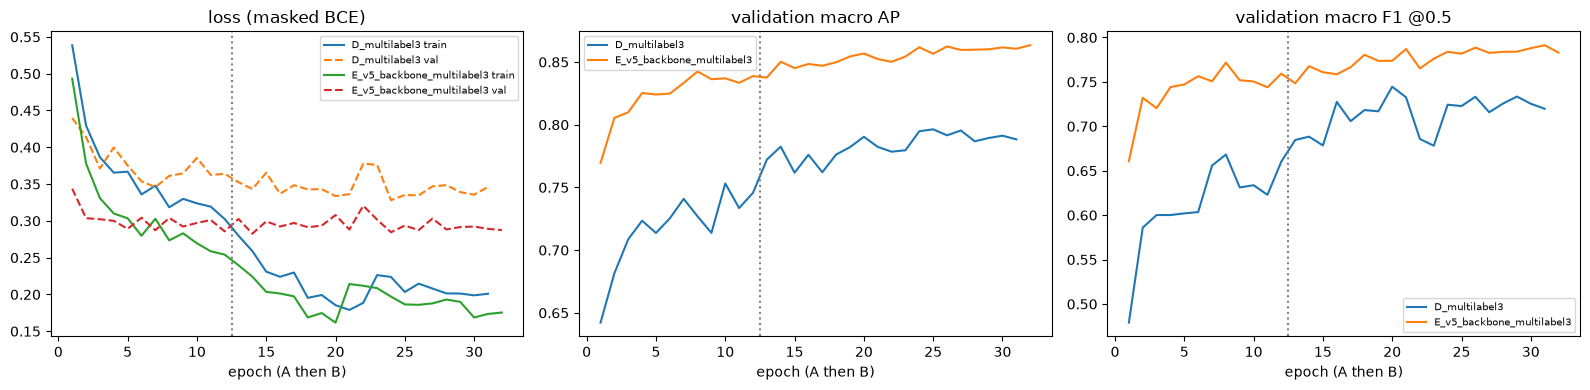

,experiment,epochs_A,epochs_B,best_step,best_phase,best_val_macro_ap,val_macro_f1_at_best
0,D_multilabel3,12,19,25,B,0.7963,0.7228
1,E_v5_backbone_multilabel3,12,20,32,B,0.8634,0.7830


In [3]:
def hist(exp):
    a = pd.read_csv(RUN / "checkpoints" / exp / "seed_42" / "phaseA_history.csv"); a["phase"] = "A"
    b = pd.read_csv(RUN / "checkpoints" / exp / "seed_42" / "phaseB_history.csv"); b["phase"] = "B"
    d = pd.concat([a, b], ignore_index=True); d["step"] = np.arange(1, len(d) + 1); return d, len(a)
H = {e: hist(e) for e in ["D_multilabel3", "E_v5_backbone_multilabel3"]}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for e, (d, na) in H.items():
    ax[0].plot(d.step, d.loss, label=f"{e} train"); ax[0].plot(d.step, d.val_loss, "--", label=f"{e} val")
    ax[1].plot(d.step, d.val_macro_ap, label=e); ax[2].plot(d.step, d.val_macro_f1, label=e)
for a_, t in zip(ax, ["loss (masked BCE)", "validation macro AP", "validation macro F1 @0.5"]):
    a_.axvline(na + 0.5, color="grey", ls=":"); a_.set_title(t); a_.set_xlabel("epoch (A then B)"); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()
rows = []
for e, (d, na) in H.items():
    i = d.val_macro_ap.idxmax(); rows.append(dict(experiment=e, epochs_A=na, epochs_B=len(d) - na, best_step=int(d.step[i]), best_phase=d.phase[i], best_val_macro_ap=d.val_macro_ap[i], val_macro_f1_at_best=d.val_macro_f1[i]))
display(pd.DataFrame(rows).round(4))

In [4]:
print("D vs E on validation images, split by V5 exposure (per condition):")
x = pd.read_csv(M / "d_vs_e_validation_by_exposure.csv"); display(x[["subset", "experiment", "condition", "pos", "neg", "precision", "recall", "f1", "ap"]].round(3))
print("selected:", json.load(open(M / "global_selection.json")).get("selected"))

D vs E on validation images, split by V5 exposure (per condition):


,subset,experiment,condition,pos,neg,precision,recall,f1,ap
0,all_validation,D_multilabel3,Acne,173,421,0.892,0.671,0.766,0.889
1,all_validation,D_multilabel3,Hyperpigmentation,233,363,0.812,0.725,0.766,0.871
2,all_validation,D_multilabel3,Eczema,55,537,0.636,0.636,0.636,0.630
3,all_validation,E_v5_backbone_multilabel3,Acne,173,421,0.876,0.855,0.865,0.925
4,all_validation,E_v5_backbone_multilabel3,Hyperpigmentation,233,363,0.902,0.708,0.793,0.912
5,all_validation,E_v5_backbone_multilabel3,Eczema,55,537,0.672,0.709,0.690,0.753
6,not_trained_by_v5,D_multilabel3,Acne,50,84,0.805,0.660,0.725,0.889
7,not_trained_by_v5,D_multilabel3,Hyperpigmentation,48,86,0.889,0.667,0.762,0.854
8,not_trained_by_v5,D_multilabel3,Eczema,18,114,0.625,0.556,0.588,0.687
9,not_trained_by_v5,E_v5_backbone_multilabel3,Acne,50,84,0.804,0.900,0.849,0.927


selected: E_v5_backbone_multilabel3


## 3. ROI MobileNetV2 (4 classes: acne, hyperpigmentation, eczema, background false positive)

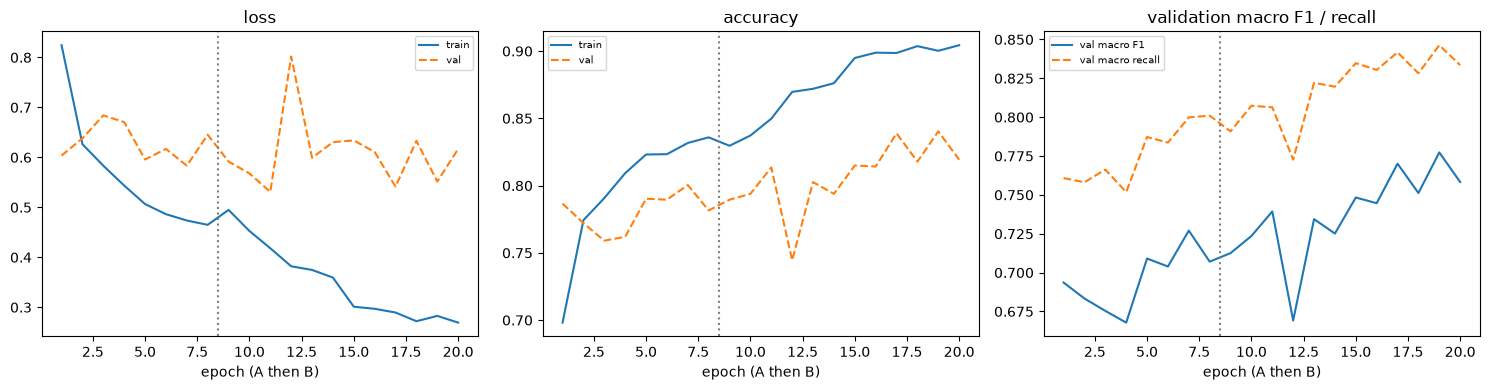

{
 "per_seed": {
  "42": {
   "frozen_backbone_val_macro_f1": 0.7270343989942278,
   "partial_finetune_val_macro_f1": 0.7773202615083622,
   "chosen": "B"
  }
 },
 "selected_seed": 42,
 "init": "imagenet"
}

ROI validation per class:


,region_class,support,precision,recall,specificity,f1,roc_auc,pr_auc,brier
0,Acne,275,0.752,0.927,0.924,0.831,0.980,0.919,0.050
1,Hyperpigmentation,132,0.620,0.864,0.944,0.722,0.968,0.827,0.047
2,Eczema,99,0.579,0.778,0.956,0.664,0.960,0.661,0.044
3,Background,872,0.986,0.817,0.980,0.893,0.967,0.982,0.103


In [5]:
ra = pd.read_csv(RUN / "checkpoints/ROI/seed_42/phaseA_history.csv"); rb = pd.read_csv(RUN / "checkpoints/ROI/seed_42/phaseB_history.csv")
r = pd.concat([ra.assign(phase="A"), rb.assign(phase="B")], ignore_index=True); r["step"] = np.arange(1, len(r) + 1)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(r.step, r.loss, label="train"); ax[0].plot(r.step, r.val_loss, "--", label="val"); ax[0].set_title("loss")
ax[1].plot(r.step, r.accuracy, label="train"); ax[1].plot(r.step, r.val_accuracy, "--", label="val"); ax[1].set_title("accuracy")
ax[2].plot(r.step, r.val_macro_f1, label="val macro F1"); ax[2].plot(r.step, r.val_macro_recall, "--", label="val macro recall"); ax[2].set_title("validation macro F1 / recall")
for a_ in ax: a_.axvline(len(ra) + 0.5, color="grey", ls=":"); a_.set_xlabel("epoch (A then B)"); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()
print(json.dumps(json.load(open(M / "roi_training_summary.json")), indent=1)[:1500])
print("\nROI validation per class:"); display(pd.read_csv(M / "roi_validation_per_class.csv").round(3))

## 4. Fusion models — 7 variants × (5 grouped folds + final fit)
Every fold and the final fit stop by early stopping. The table lists the epochs each used and its last validation loss (fold sizes are small, so curves are noisy).

42 fits found (expected 42)


fit,final,fold_0,fold_1,fold_2,fold_3,fold_4
variant,,,,,,
full,21,23,21,21,29,39
global_yolo,24,51,28,27,47,83
global_only,24,51,28,31,37,41
roi_only,24,21,21,21,27,38
no_acne_evidence,21,22,22,21,28,25
no_eczema_evidence,21,23,21,38,38,25
no_hyper_evidence,21,23,22,21,41,34


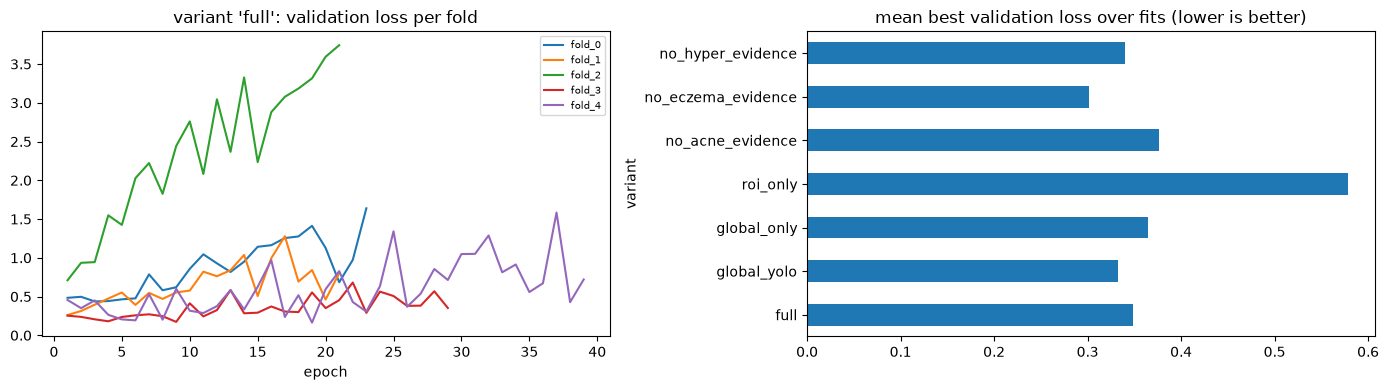

In [6]:
VARS = ["full", "global_yolo", "global_only", "roi_only", "no_acne_evidence", "no_eczema_evidence", "no_hyper_evidence"]
def fold_hist(var, fold):
    fs = sorted(glob.glob(str(RUN / "fusion" / "recovery" / var / "seed_42" / fold / "attempt_*" / "epoch_*.history.csv")))
    return pd.read_csv(fs[-1]) if fs else None
rows = []
for v in VARS:
    for f in ["fold_0", "fold_1", "fold_2", "fold_3", "fold_4", "final"]:
        h = fold_hist(v, f)
        if h is not None: rows.append(dict(variant=v, fit=f, epochs=len(h), best_val_loss=h.val_loss.min(), last_val_loss=h.val_loss.iloc[-1]))
FT = pd.DataFrame(rows); print(f"{len(FT)} fits found (expected 42)")
display(FT.pivot(index="variant", columns="fit", values="epochs").reindex(VARS))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for f in ["fold_0", "fold_1", "fold_2", "fold_3", "fold_4"]:
    h = fold_hist("full", f); ax[0].plot(h.epoch, h.val_loss, label=f)
ax[0].set_title("variant 'full': validation loss per fold"); ax[0].legend(fontsize=7); ax[0].set_xlabel("epoch")
FT.groupby("variant").best_val_loss.mean().reindex(VARS).plot.barh(ax=ax[1]); ax[1].set_title("mean best validation loss over fits (lower is better)")
plt.tight_layout(); plt.show()

## 5. Development evaluation (fusion split, out-of-fold)
Out-of-fold means each image was scored by a model that did not train on it. **This is not a V5 comparison and not a test result.** About 85 % of these images were in V5's training data.

condition,Acne,Eczema,Hyperpigmentation
variant,,,
Full fusion (+ROI),0.889,0.700,0.902
Global + YOLO evidence,0.884,0.746,0.911
Global only (recalibrated),0.877,0.716,0.894
ROI branch only,0.836,0.635,0.881


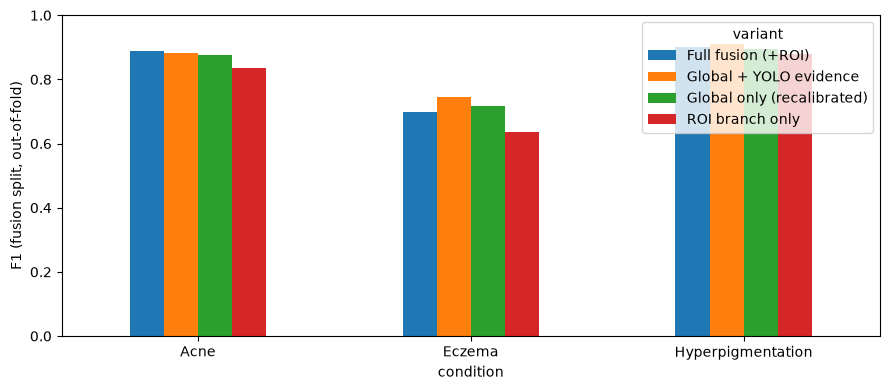

per-condition detail:


,variant,condition,n_evaluable,pos,neg,precision,recall,specificity,f1
0,Global only (recalibrated),Acne,353,111,242,0.921,0.838,0.967,0.877
1,Global only (recalibrated),Hyperpigmentation,352,124,228,0.902,0.887,0.947,0.894
2,Global only (recalibrated),Eczema,357,33,324,0.706,0.727,0.969,0.716
3,Global + YOLO evidence,Acne,353,111,242,0.876,0.892,0.942,0.884
4,Global + YOLO evidence,Hyperpigmentation,352,124,228,0.918,0.903,0.956,0.911
5,Global + YOLO evidence,Eczema,357,33,324,0.735,0.758,0.972,0.746
6,Full fusion (+ROI),Acne,353,111,242,0.877,0.901,0.942,0.889
7,Full fusion (+ROI),Hyperpigmentation,352,124,228,0.910,0.895,0.952,0.902
8,Full fusion (+ROI),Eczema,357,33,324,0.778,0.636,0.981,0.700
9,ROI branch only,Acne,353,111,242,0.844,0.829,0.930,0.836


In [7]:
names = {"global_only": "Global only (recalibrated)", "global_yolo": "Global + YOLO evidence", "full": "Full fusion (+ROI)", "roi_only": "ROI branch only"}
T = pd.concat([pd.read_csv(M / f"development_{k}_per_condition.csv").assign(variant=v) for k, v in names.items()], ignore_index=True)
display(T.pivot(index="variant", columns="condition", values="f1").round(3))
ax = T.pivot(index="condition", columns="variant", values="f1").plot.bar(figsize=(9, 4), rot=0); ax.set_ylabel("F1 (fusion split, out-of-fold)"); ax.set_ylim(0, 1); plt.tight_layout(); plt.show()
print("per-condition detail:"); display(T[["variant", "condition", "n_evaluable", "pos", "neg", "precision", "recall", "specificity", "f1"]].round(3))

In [8]:
s = json.load(open(M / "development_oof_summary.json"))
fn = s["final_normal"]; s1 = s["stage1_normal"]
print(f"Derived-Normal decision (fusion split, n={s['n']}):")
print(f"  Stage 1 accepted {s1['accepted_n']} of {s1['reference_n']} references as Normal-decidable; abstention rate {s1['abstention_rate']:.1%}")
print(f"  Final (after Stage 2) accepted {fn['accepted_n']}; abstention rate {fn['abstention_rate']:.1%}; false Normal {fn['false_normal']}; recall over ALL references {fn['recall_all_references']:.1%}")
print("  A low error on accepted cases must be read together with this abstention rate; V5 never abstains.")

Derived-Normal decision (fusion split, n=360):
  Stage 1 accepted 12 of 347 references as Normal-decidable; abstention rate 96.5%
  Final (after Stage 2) accepted 74; abstention rate 78.7%; false Normal 1; recall over ALL references 40.6%
  A low error on accepted cases must be read together with this abstention rate; V5 never abstains.


## 6. Calibration of the fusion variants (out-of-fold)

In [9]:
c = pd.read_csv(M / "fusion_calibration_oof.csv"); display(c.round(4).head(30))

,variant,condition,brier_raw,brier_calibrated,ece_raw,ece_calibrated,calibrated,threshold
0,full,Acne,0.0649,0.0609,0.0521,0.0386,True,0.43
1,full,Hyperpigmentation,0.0585,0.0587,0.0341,0.0211,True,0.34
2,full,Eczema,0.0651,0.0437,0.0719,0.0180,True,0.33
3,global_yolo,Acne,0.0632,0.0582,0.0358,0.0237,True,0.42
4,global_yolo,Hyperpigmentation,0.0572,0.0562,0.0337,0.0199,True,0.37
5,global_yolo,Eczema,0.0600,0.0454,0.0712,0.0285,True,0.27
6,global_only,Acne,0.0653,0.0627,0.0393,0.0206,True,0.51
7,global_only,Hyperpigmentation,0.0664,0.0651,0.0427,0.0282,True,0.39
8,global_only,Eczema,0.0713,0.0450,0.0912,0.0258,True,0.25
9,roi_only,Acne,0.0877,0.0822,0.0546,0.0098,True,0.46


## 7. Stage rules

In [10]:
display(pd.read_csv(M / "development_oof_stage_per_condition.csv").round(3))

,condition,n_evaluable,pos,neg,precision,recall,specificity,f1,tp,fp,fn,tn,ap,roc_auc,stage
0,Acne,12,0,12,NaN,NaN,1.000,NaN,0,0,0,12,0.950,0.971,stage1
1,Hyperpigmentation,12,0,12,NaN,NaN,1.000,NaN,0,0,0,12,0.952,0.958,stage1
2,Eczema,12,1,11,1.000,1.000,1.000,1.00,1,0,0,11,0.711,0.915,stage1
3,Acne,74,7,67,0.667,0.857,0.955,0.75,6,3,1,64,0.941,0.969,final
4,Hyperpigmentation,74,25,49,1.000,0.960,1.000,0.98,24,0,1,49,0.956,0.962,final
5,Eczema,74,2,72,1.000,1.000,1.000,1.00,2,0,0,72,0.721,0.914,final


## 8. V5 vs V6 on validation images V5 never trained on  ← the thesis comparison
**Set:** validation images not in V5's training data (by id, MD5 and leakage group), fully verified labels. **Systems:** V5 argmax (its own decision rule), V5 with thresholds tuned on the fusion split (A2), Global E, Global+YOLO (E), Full fusion (F), ROI only, Global recalibrated. **Thresholds** come from the fusion split only. **Intervals** are 95 % bootstrap over leakage groups; an interval that includes 0 means the data do not show a difference (it does not show equivalence). **Caveat:** validation was used to select Global E over D and to stop ROI training, so V6 may look slightly better here than on fresh photos; V5 was not tuned on it. Abstention (system G) is not in this table.

,system,n,hp_pos,hp_missed_as_no_condition,hp_recall,all_neg,all_neg_flagged_hp,f1_acne,f1_hyper,f1_eczema,macro_f1
0,A_v5_argmax,132,47,9,0.511,26,1,0.835,0.658,0.718,0.737
1,A2_v5_thresholded,132,47,7,0.617,26,2,0.836,0.725,0.667,0.743
2,B_global_E,132,47,10,0.574,26,3,0.852,0.701,0.647,0.733
3,E_global_plus_yolo,132,47,10,0.574,26,2,0.870,0.711,0.632,0.737
4,F_full_fusion,132,47,8,0.702,26,2,0.862,0.759,0.645,0.755
5,D_roi_only,132,47,9,0.617,26,1,0.830,0.734,0.629,0.731
6,X_global_recalibrated,132,47,11,0.574,26,2,0.874,0.711,0.595,0.726


,system,vs,metric,difference,ci_lo,ci_hi,better_when,excludes_zero
0,B_global_E,A_v5_argmax,macro_f1,-0.003,-0.093,0.083,higher,False
1,B_global_E,A_v5_argmax,hp_missed_rate,0.021,-0.047,0.105,lower,False
2,B_global_E,A_v5_argmax,false_alarm_rate,0.077,0.000,0.200,lower,False
3,E_global_plus_yolo,A_v5_argmax,macro_f1,0.001,-0.084,0.074,higher,False
4,E_global_plus_yolo,A_v5_argmax,hp_missed_rate,0.021,0.000,0.076,lower,False
5,E_global_plus_yolo,A_v5_argmax,false_alarm_rate,0.038,-0.081,0.185,lower,False
6,F_full_fusion,A_v5_argmax,macro_f1,0.019,-0.086,0.112,higher,False
7,F_full_fusion,A_v5_argmax,hp_missed_rate,-0.021,-0.093,0.053,lower,False
8,F_full_fusion,A_v5_argmax,false_alarm_rate,0.038,0.000,0.136,lower,False


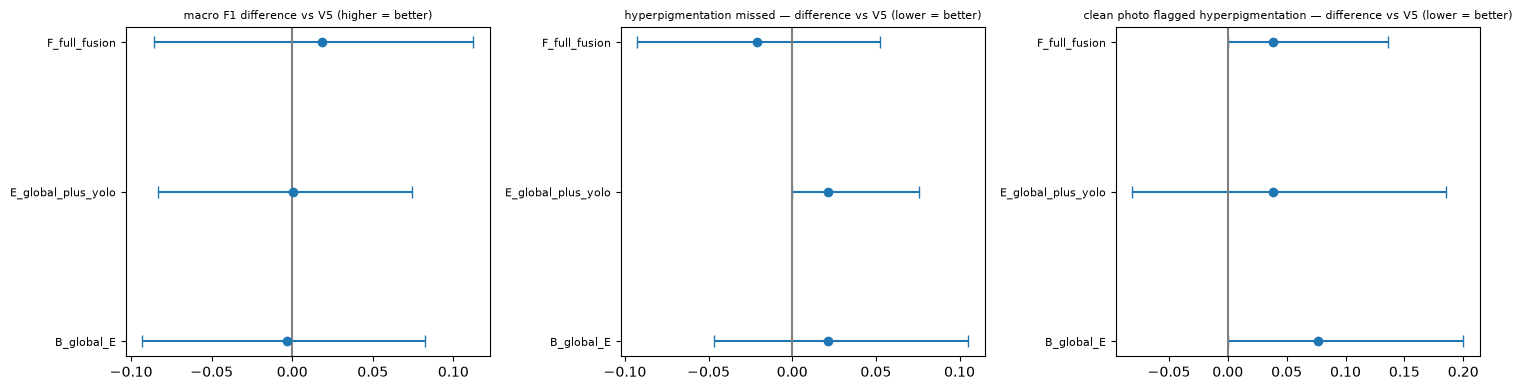

In [11]:
fair = pd.read_csv(M / "v5_vs_v6_fair_set.csv"); pair = pd.read_csv(M / "v5_vs_v6_fair_set_paired.csv")
display(fair.round(3)); display(pair.round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, met, title in zip(ax, ["macro_f1", "hp_missed_rate", "false_alarm_rate"], ["macro F1 difference vs V5 (higher = better)", "hyperpigmentation missed — difference vs V5 (lower = better)", "clean photo flagged hyperpigmentation — difference vs V5 (lower = better)"]):
    p = pair[pair.metric == met]; y = np.arange(len(p))
    a_.errorbar(p.difference, y, xerr=[p.difference - p.ci_lo, p.ci_hi - p.difference], fmt="o", capsize=4); a_.axvline(0, color="grey"); a_.set_yticks(y); a_.set_yticklabels(p.system, fontsize=8); a_.set_title(title, fontsize=8)
plt.tight_layout(); plt.show()

In [12]:
# Pre-registered criterion (v6/THESIS_TRACKER.md, fixed before results): V6 = Global + YOLO fusion counts as an improvement only if
# (a) hyperpigmentation-missed AND clean-flagged are each not worse than V5, and at least one is better with a 95% interval that excludes zero, and
# (b) Acne and Eczema F1 are each not more than 0.05 below V5.
f = fair.set_index("system"); A = f.loc["A_v5_argmax"]
for name in ["E_global_plus_yolo", "F_full_fusion"]:
    E = f.loc[name]; P = pair[(pair.system == name) & (pair.metric.isin(["hp_missed_rate", "false_alarm_rate"]))]
    a_notworse = bool(E.hp_missed_as_no_condition <= A.hp_missed_as_no_condition and E.all_neg_flagged_hp <= A.all_neg_flagged_hp)
    a_sig = bool(((P.difference < 0) & P.excludes_zero).any())
    b_ok = bool(E.f1_acne >= A.f1_acne - 0.05 and E.f1_eczema >= A.f1_eczema - 0.05)
    print(f"{name}: (a) not worse on both errors = {a_notworse}; one better with CI excluding 0 = {a_sig}; (b) acne/eczema F1 within 0.05 = {b_ok}  ->  {'MET' if (a_notworse and a_sig and b_ok) else 'NOT MET: report as no clear improvement'}")
    print(f"    hyper missed {int(E.hp_missed_as_no_condition)} vs V5 {int(A.hp_missed_as_no_condition)} | clean flagged {int(E.all_neg_flagged_hp)} vs {int(A.all_neg_flagged_hp)} | eczema F1 {E.f1_eczema:.3f} vs {A.f1_eczema:.3f}")

E_global_plus_yolo: (a) not worse on both errors = False; one better with CI excluding 0 = False; (b) acne/eczema F1 within 0.05 = False  ->  NOT MET: report as no clear improvement
    hyper missed 10 vs V5 9 | clean flagged 2 vs 1 | eczema F1 0.632 vs 0.718
F_full_fusion: (a) not worse on both errors = False; one better with CI excluding 0 = False; (b) acne/eczema F1 within 0.05 = False  ->  NOT MET: report as no clear improvement
    hyper missed 8 vs V5 9 | clean flagged 2 vs 1 | eczema F1 0.645 vs 0.718


### 8b. Eczema on the same fair set (post-hoc diagnostic — a hypothesis, not a result)
Only 18 eczema-positive photos. The V6 models *rank* eczema better than V5 (higher AP/AUC) but lose at the calibrated cutoff (thresholds were set on only 33 eczema positives in the fusion split). No threshold was re-tuned on these photos.

In [13]:
e = pd.read_csv(M / "eczema_fair_set_diagnostic.csv"); print(e.groupby("truth").size().to_dict())
pos = e[e.truth == "eczema"]; print(f"eczema positives {len(pos)}: V5 found {int(pos.v5_says.sum())}, full fusion found {int(pos.full_says.sum())}")
display(e[(e.v5_says == (e.truth == "eczema")) & (e.full_says != (e.truth == "eczema"))])

{'eczema': 18, 'no eczema': 114}
eczema positives 18: V5 found 14, full fusion found 10


,image_id,origin,truth,v5_score,full_score,v5_says,full_says
8,img_000810,source_dataset,eczema,0.668,0.179,True,False
89,img_012879,source_dataset,eczema,0.969,0.210,True,False
91,img_013087,source_dataset,eczema,0.541,0.150,True,False
95,img_014033,source_dataset,eczema,0.470,0.274,True,False
96,img_014106,source_dataset,eczema,0.939,0.220,True,False
97,img_014238,source_dataset,eczema,0.904,0.237,True,False


## 9. Export and ONNX faithfulness
The notebook's own check compared Keras on the **GPU** with ONNX on the **CPU** and flagged everything outside 1e-4. A follow-up compared the same images three ways: the gap is GPU-vs-CPU numeric noise, not an export defect.

In [14]:
ex = json.load(open(RUN / "export" / "v6_export_status.json")); print({k: v.get("status") for k, v in ex.items()})
v = json.load(open(RUN / "export" / "v6_keras_vs_onnx_verification.json"))
display(pd.DataFrame([dict(component=k, status=x.get("status"), max_abs_diff=max(x.get("max_abs_diff_per_output", [np.nan])), within_1e_4=x.get("within_tolerance")) for k, x in v.items() if isinstance(x, dict)]).round(5))
pc = RUN / "export" / "v6_global_features_parity_check.csv"
if pc.exists(): print("Global feature model, 160 validation photos x 3 conditions (Keras GPU / Keras CPU / ONNX CPU):"); display(pd.read_csv(pc).round(5))
else: print("(follow-up parity table not found in this folder)")

{'global_features': 'exported', 'roi_features': 'exported', 'fusion_global_only_seed42': 'exported', 'fusion_global_yolo_seed42': 'exported', 'fusion_full_seed42': 'exported'}


,component,status,max_abs_diff,within_1e_4
0,global_features,compared,0.04257,False
1,roi_features,compared,0.05155,False
2,fusion_global_only_seed42,compared,0.00047,False
3,fusion_global_yolo_seed42,compared,0.00051,False
4,fusion_full_seed42,compared,0.00055,False


Global feature model, 160 validation photos x 3 conditions (Keras GPU / Keras CPU / ONNX CPU):


,pair,max_abs_diff_embedding,max_abs_diff_logits,decisions_flipped_at_0_5,decisions_flipped_at_tuned_thresholds
0,Keras GPU vs Keras CPU,0.05241,0.06956,0,1
1,Keras CPU vs ONNX CPU,0.00004,0.00005,0,0
2,Keras GPU vs ONNX CPU,0.05244,0.06960,0,1


## 10. What this run does and does not show
- **Does show:** the pipeline trains end to end and reproduces (audit chain intact, originals unchanged, 35 of 37 unit tests pass with 2 skipped by design); components export to ONNX and match Keras on CPU.
- **Does not show:** that V6 beats V5. On validation images V5 never trained on, the pre-registered criterion was **not met** (section 8). Global E and the fusion models rank conditions somewhat better than V5, and acne F1 is higher, but the error rates the thesis targets are not significantly better and eczema F1 fell below the allowed margin.
- **Not done:** the locked test (no expert labels), an independent labelled set, dermatologist validation, C# parity, multi-seed variability.